<a href="https://colab.research.google.com/github/AlbertPuentes/Semana_7_Algoritmo_Genetico_Simple-/blob/main/Semana_7_Algoritmo_Genetico_Simple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Semana 7 — Implementación de un Algoritmo Genético Simple
**CADI:** Machine Learning y Algoritmos Genéticos  
**Universidad de Cundinamarca**

## Propósito de la práctica
Implementar y experimentar con un **Algoritmo Genético Simple** usando Python y la librería `geneticalgorithm2`.

Durante aproximadamente **40 minutos**, cada grupo deberá:

1. Ejecutar una configuración inicial o **línea base**.
2. Realizar **mínimo 3 experimentos** modificando parámetros del algoritmo.
3. Comparar los resultados.
4. Elegir su mejor configuración.
5. Preparar una conclusión breve para socializar.




### Pregunta central
**¿Cómo cambian la calidad de la solución y el tiempo de ejecución cuando modificamos los parámetros del Algoritmo Genético?**


## 1. Instalar la librería

In [1]:
!pip -q install geneticalgorithm2

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.2/67.2 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 1.1 MB/s eta 0:00:00


## 2. Importar librerías

In [2]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from geneticalgorithm2 import GeneticAlgorithm2 as ga

print("Librerías cargadas correctamente.")


Librerías cargadas correctamente.



## 3. Problema de optimización

Queremos encontrar los valores de **x** y **y** que minimicen la función:

\[
f(x,y) = (x-3)^2 + (y+2)^2
\]

El mínimo teórico se encuentra en:

\[
x=3,\quad y=-2,\quad f(x,y)=0
\]

El Algoritmo Genético **no recibe directamente esa respuesta**. Debe explorar el espacio de búsqueda y aproximarse a ella.

Para esta práctica:

- `x ∈ [-10, 10]`
- `y ∈ [-10, 10]`
- Una solución candidata o **individuo** será `[x, y]`.
- La función objetivo corresponde al valor que queremos **minimizar**.


In [3]:

def funcion_objetivo(X):
    x, y = X
    return (x - 3)**2 + (y + 2)**2

limites = [[-10, 10], [-10, 10]]

print("Ejemplo: f(0, 0) =", funcion_objetivo([0, 0]))
print("Óptimo teórico: f(3, -2) =", funcion_objetivo([3, -2]))


Ejemplo: f(0, 0) = 13
Óptimo teórico: f(3, -2) = 0



## 4. ¿Qué parámetros vamos a experimentar?

En esta práctica modificaremos principalmente:

- **Tamaño de población (`population_size`)**: cantidad de individuos por generación.
- **Número de generaciones (`max_num_iteration`)**: cuántas veces evoluciona la población.
- **Probabilidad de mutación (`mutation_probability`)**: frecuencia con que aparecen cambios aleatorios.
- **Probabilidad de cruce (`crossover_probability`)**: frecuencia con que dos progenitores recombinan información.

Mantendremos constantes otros parámetros para facilitar la comparación.


## 5. Función auxiliar para ejecutar y registrar experimentos

In [4]:

resultados = []

def ejecutar_experimento(
    nombre,
    poblacion=40,
    generaciones=60,
    mutacion=0.10,
    cruce=0.70,
    seed=42,
    mostrar_curva=True
):
    parametros = {
        'max_num_iteration': generaciones,
        'population_size': poblacion,
        'mutation_probability': mutacion,
        'elit_ratio': 0.02,
        'parents_portion': 0.30,
        'crossover_probability': cruce,
        'crossover_type': 'uniform',
        'mutation_type': 'uniform_by_center',
        'selection_type': 'roulette',
        'max_iteration_without_improv': None
    }

    modelo = ga(
        dimension=2,
        variable_type='real',
        variable_boundaries=limites,
        algorithm_parameters=parametros
    )

    inicio = time.perf_counter()

    resultado = modelo.run(
        function=funcion_objetivo,
        no_plot=True,
        progress_bar_stream=None,
        disable_printing=True,
        seed=seed
    )

    tiempo = time.perf_counter() - inicio

    mejor_variable = np.array(resultado.variable, dtype=float)
    mejor_score = float(resultado.score)

    fila = {
        "Experimento": nombre,
        "Población": poblacion,
        "Generaciones": generaciones,
        "Mutación": mutacion,
        "Cruce": cruce,
        "x": mejor_variable[0],
        "y": mejor_variable[1],
        "Mejor fitness": mejor_score,
        "Tiempo (s)": tiempo
    }
    resultados.append(fila)

    print(f"--- {nombre} ---")
    print(f"Mejor solución: x={mejor_variable[0]:.6f}, y={mejor_variable[1]:.6f}")
    print(f"Mejor fitness: {mejor_score:.8f}")
    print(f"Tiempo: {tiempo:.4f} s")

    if mostrar_curva:
        plt.figure(figsize=(7, 4))
        plt.plot(modelo.report)
        plt.xlabel("Generación")
        plt.ylabel("Mejor fitness")
        plt.title(f"Convergencia — {nombre}")
        plt.grid(alpha=0.25)
        plt.show()

    return modelo, resultado



## 6. Línea base

Ejecuten primero **sin cambiar nada**.

Registren:

- mejor solución;
- mejor fitness;
- tiempo;
- forma de la curva de convergencia.

Después de esta ejecución comenzará la experimentación del grupo.


--- Línea base ---
Mejor solución: x=2.965824, y=-2.004035
Mejor fitness: 0.00118431
Tiempo: 0.0394 s


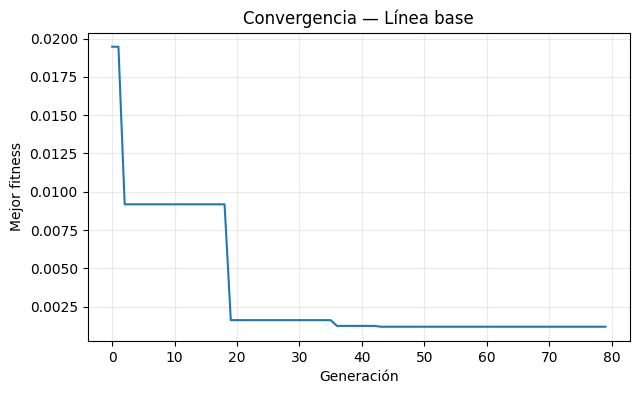

In [14]:

modelo_base, resultado_base = ejecutar_experimento(
    nombre="Línea base",
    poblacion=50,
    generaciones=80,
    mutacion=0.10,
    cruce=0.70
)



## 7. Experimento


> ¿Qué esperamos que ocurra y por qué?

Luego ejecuten y comparen contra la línea base.


--- Prueba Inicial ---
Mejor solución: x=2.997689, y=-1.990692
Mejor fitness: 0.00009197
Tiempo: 0.0314 s


/usr/local/lib/python3.13/dist-packages/geneticalgorithm2/geneticalgorithm2.py:189: UserWarning: crossover_probability is deprecated and will be removed in version 7. Reason: it's old and has no sense
  warnings.warn(


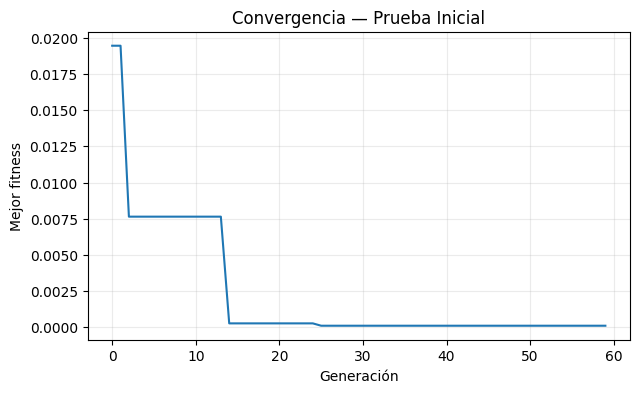

In [10]:

# Prueba inicial
modelo_0, resultado_0 = ejecutar_experimento(
    nombre="Prueba Inicial",
    poblacion=40,
    generaciones=60,
    mutacion=0.10,
    cruce=0.70
)


## 8. Prueba 1

--- Prueba 1 ---
Mejor solución: x=2.999458, y=-2.007190
Mejor fitness: 0.00005199
Tiempo: 0.0891 s


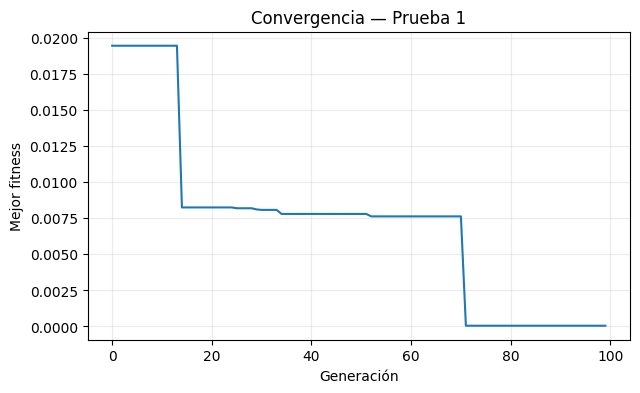

In [11]:

# PRUEBA 1
modelo_1, resultado_1 = ejecutar_experimento(
    nombre="Prueba 1",
    poblacion=58,
    generaciones=120,
    mutacion=0.05,
    cruce=0.74
)


## 9. Prueba 2

--- Prueba 2 ---
Mejor solución: x=2.886135, y=-2.180240
Mejor fitness: 0.04545187
Tiempo: 0.0124 s


/usr/local/lib/python3.13/dist-packages/geneticalgorithm2/geneticalgorithm2.py:189: UserWarning: crossover_probability is deprecated and will be removed in version 7. Reason: it's old and has no sense
  warnings.warn(


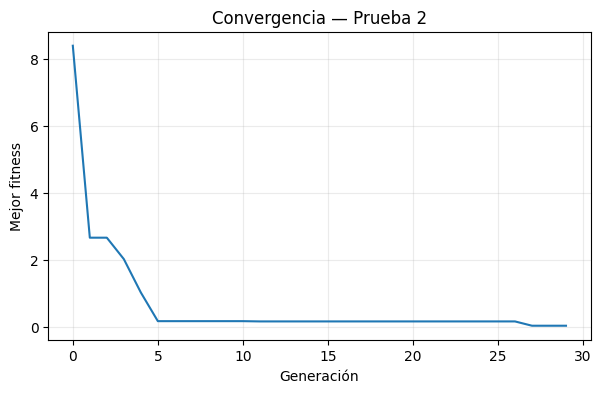

In [12]:

# EXPERIMENTO 2 — MODIFICAR LOS VALORES
modelo_2, resultado_2 = ejecutar_experimento(
    nombre="Prueba 2",
    poblacion=76,
    generaciones=52,
    mutacion=0.35,
    cruce=0.80
)


## 10. Prueba 3

--- Prueba 3 ---
Mejor solución: x=2.997689, y=-1.935777
Mejor fitness: 0.00412988
Tiempo: 0.0479 s


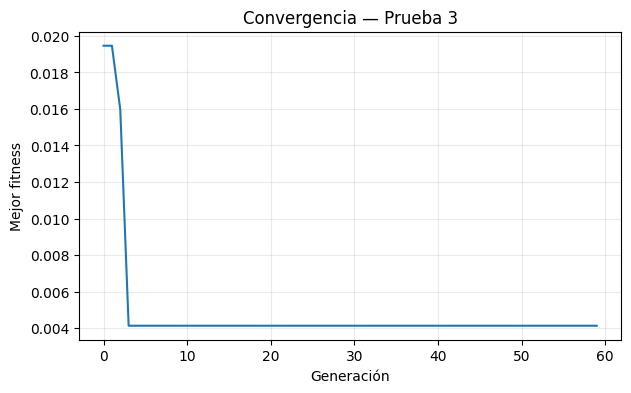

In [ ]:

# EXPERIMENTO 3 — MODIFICAR LOS VALORES
modelo_3, resultado_3 = ejecutar_experimento(
    nombre="Prueba 3",
    poblacion=90,
    generaciones=60,
    mutacion=0.65,
    cruce=0.70
)


## 11. Prueba 4

/usr/local/lib/python3.13/dist-packages/geneticalgorithm2/geneticalgorithm2.py:189: UserWarning: crossover_probability is deprecated and will be removed in version 7. Reason: it's old and has no sense
  warnings.warn(


--- Prueba 4 ---
Mejor solución: x=3.004341, y=-2.012535
Mejor fitness: 0.00017598
Tiempo: 0.0606 s


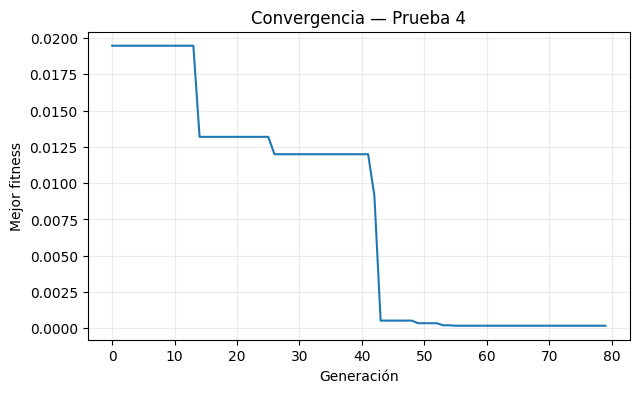

In [13]:
# Prueba 4
modelo_4, resultado_4 = ejecutar_experimento(
    nombre="Prueba 4",
    poblacion=90,
    generaciones=130,
    mutacion=0.10,
    cruce=0.95
)


## 12. Comparar resultados

La siguiente tabla reúne automáticamente las ejecuciones realizadas.

### Preguntas para analizar
1. ¿Qué configuración obtuvo el menor fitness?
2. ¿Cuál tardó más?
3. ¿Más población produjo necesariamente una mejor solución?
4. ¿Más generaciones siempre mejoraron el resultado?
5. ¿Qué efecto observaron al modificar la mutación o el cruce?


In [ ]:

tabla_resultados = pd.DataFrame(resultados)
tabla_resultados


In [ ]:

# Comparación visual del fitness obtenido
plt.figure(figsize=(9, 4))
plt.bar(tabla_resultados["Experimento"], tabla_resultados["Mejor fitness"])
plt.ylabel("Mejor fitness (menor es mejor)")
plt.title("Comparación entre experimentos")
plt.xticks(rotation=15)
plt.show()



## 13. Construir la mejor configuración del grupo

Con base en lo observado, definan una configuración final.

**No se trata de poner todos los parámetros al máximo.**  
Busquen una combinación que produzca una solución de buena calidad y un tiempo de ejecución razonable.

Modifiquen la siguiente celda.


In [ ]:

# MEJOR CONFIGURACIÓN DEL GRUPO
modelo_final, resultado_final = ejecutar_experimento(
    nombre="Mejor configuración",
    poblacion=50,       # <-- decisión del grupo
    generaciones=80,   # <-- decisión del grupo
    mutacion=0.12,      # <-- decisión del grupo
    cruce=0.75          # <-- decisión del grupo
)


## 14. Tabla final

In [ ]:

tabla_final = pd.DataFrame(resultados)
tabla_final.sort_values("Mejor fitness")



## 15. Conclusión para la socialización

Responder:

1. **¿Qué parámetros modificaron?**
2. **¿Qué ocurrió con el desempeño?**
3. **¿Cuál fue su mejor configuración?**
4. **¿Por qué consideran que funcionó mejor?**
5. **¿Qué aprendieron sobre el comportamiento de un Algoritmo Genético?**

### Idea clave
Un Algoritmo Genético es **estocástico**. Por eso, una sola ejecución no basta para afirmar que una configuración es universalmente mejor.

Para comparar configuraciones con mayor rigor, deberían repetirse varias veces y analizar tanto la calidad de la solución como el costo computacional.



## 16. Exploración opcional — comportamiento estocástico

Si terminan antes de tiempo:

1. Ejecuten dos veces la misma configuración cambiando `seed=42` por otro número.
2. Comparen los resultados.
3. Respondan:

> Si el algoritmo y los parámetros son iguales, ¿por qué pueden cambiar los resultados?

Esto permite observar directamente el componente aleatorio de la computación evolutiva.


In [ ]:

# OPCIONAL
modelo_extra, resultado_extra = ejecutar_experimento(
    nombre="Misma configuración, otra semilla",
    poblacion=40,
    generaciones=60,
    mutacion=0.10,
    cruce=0.70,
    seed=99
)
